In [5]:
!git clone https://github.com/sadi2003q/Seizure-Detection-.git

fatal: destination path 'Seizure-Detection-' already exists and is not an empty directory.


In [10]:
import sys, os

# ── EDIT THESE TWO LINES ─────────────────────────────────────────────
PROJECT_DIR = '/kaggle/working/Seizure-Detection-'                     # folder that contains base.py, models/, etc.
CSV_PATH    = '/kaggle/input/datasets/makkisakib1/chb-mit-seizuredetection/Epileptic_Sub_Eve_ID.csv'   # your CSV file
# ─────────────────────────────────────────────────────────────────────

sys.path.insert(0, PROJECT_DIR)
print('Project files found:', sorted(f for f in os.listdir(PROJECT_DIR) if f.endswith('.py')))
print('CSV exists         :', os.path.exists(CSV_PATH))

Project files found: ['base.py', 'experiment.py', 'loso.py', 'plots.py', 'preprocessing.py', 'report.py']
CSV exists         : True


In [11]:
from preprocessing import prepare_data, load_raw
from models import LogisticModel, XGBoostModel, MambaModel
from experiment import train, evaluate
from loso import run_loso
from report import report, compare, loso_report, loso_compare
from plots import plot, plot_compare, plot_loso

In [12]:
X, y, g = prepare_data(CSV_PATH)          # baseline: one global scaler fitted on the training patients

# To use per-patient normalisation for EVERYTHING below, use this line instead:
# X, y, g = prepare_data(CSV_PATH, per_patient_norm='interictal')

train      n= 62182  seizure=49.0%  patients=['chb01', 'chb02', 'chb03', 'chb04', 'chb05', 'chb06', 'chb07', 'chb08', 'chb09', 'chb10', 'chb11', 'chb12']
validation n=  5750  seizure=48.6%  patients=['chb14', 'chb15']
test       n= 13494  seizure=55.3%  patients=['chb16', 'chb17', 'chb18', 'chb19', 'chb20', 'chb22']


train      n= 62182  seizure=49.0%  patients=['chb01', 'chb02', 'chb03', 'chb04', 'chb05', 'chb06', 'chb07', 'chb08', 'chb09', 'chb10', 'chb11', 'chb12']
validation n=  5750  seizure=48.6%  patients=['chb14', 'chb15']
test       n= 13494  seizure=55.3%  patients=['chb16', 'chb17', 'chb18', 'chb19', 'chb20', 'chb22']


Fitting LogReg:   0%|          | 0/1 [00:00<?, ?it/s]

Per-patient normalisation 'all': statistics from all of each patient's windows (depends on seizure fraction); smallest reference set = 756 windows
train      n= 62182  seizure=49.0%  patients=['chb01', 'chb02', 'chb03', 'chb04', 'chb05', 'chb06', 'chb07', 'chb08', 'chb09', 'chb10', 'chb11', 'chb12']
validation n=  5750  seizure=48.6%  patients=['chb14', 'chb15']
test       n= 13494  seizure=55.3%  patients=['chb16', 'chb17', 'chb18', 'chb19', 'chb20', 'chb22']


Fitting LogReg:   0%|          | 0/1 [00:00<?, ?it/s]

Per-patient normalisation 'interictal': statistics from each patient's seizure-free windows (assumes a seizure-free calibration recording per new patient); smallest reference set = 237 windows
train      n= 62182  seizure=49.0%  patients=['chb01', 'chb02', 'chb03', 'chb04', 'chb05', 'chb06', 'chb07', 'chb08', 'chb09', 'chb10', 'chb11', 'chb12']
validation n=  5750  seizure=48.6%  patients=['chb14', 'chb15']
test       n= 13494  seizure=55.3%  patients=['chb16', 'chb17', 'chb18', 'chb19', 'chb20', 'chb22']


Fitting LogReg:   0%|          | 0/1 [00:00<?, ?it/s]

,Model,Accuracy,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Acc_at_0_5
0,LogReg | norm=interictal,0.6686,0.4232,0.9725,0.5855,0.8361,0.8801,0.7715
1,LogReg | norm=None,0.5099,0.1163,0.9972,0.2079,0.7272,0.7999,0.6707
2,LogReg | norm=all,0.4976,0.1301,0.9526,0.2227,0.6849,0.6958,0.6361


Best by ROC-AUC: LogReg | norm=interictal (0.8361). Gap to LogReg | norm=None: 0.1089.


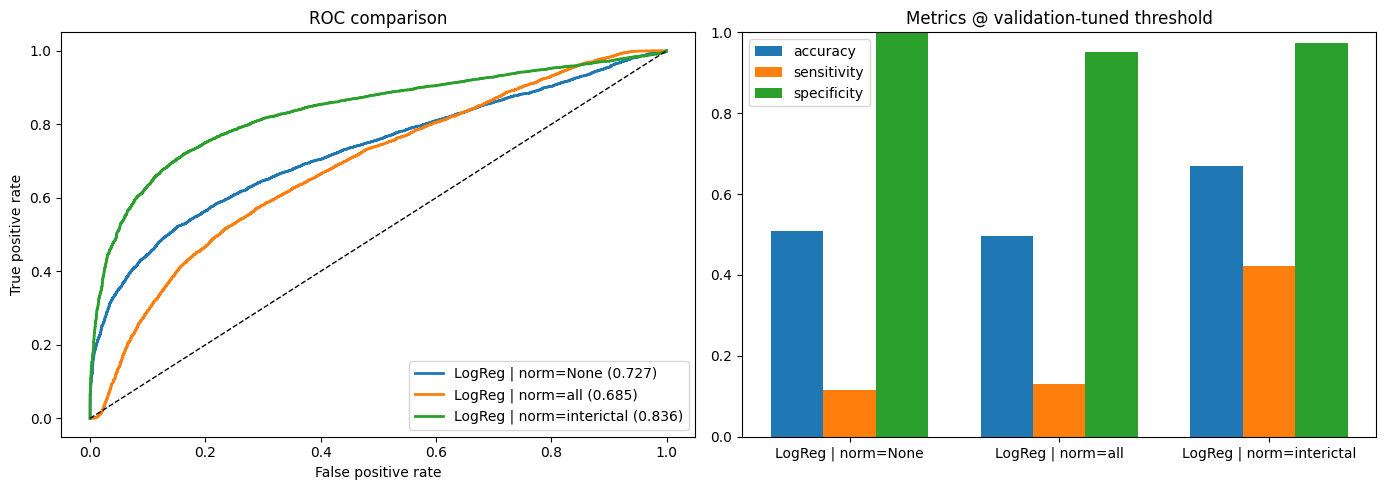

In [13]:
runs = []
for mode in [None, 'all', 'interictal']:
    Xn, yn, gn = prepare_data(CSV_PATH, per_patient_norm=mode)
    m = train(LogisticModel.build(C=0.1, max_iter=2000), Xn['train'], yn['train'])
    s = evaluate(m, Xn['validation'], yn['validation'], Xn['test'], yn['test'], gn['test'])
    s['name'] = f'LogReg | norm={mode}'
    runs.append(s)
compare(runs); plot_compare(runs)

Fitting LogReg:   0%|          | 0/1 [00:00<?, ?it/s]

  LogReg  -  results on UNSEEN test patients
Parameters used: {'C': 0.1, 'solver': 'lbfgs', 'max_iter': 2000, 'class_weight': None, 'random_state': 42}
              Metric  @ 0.50  @ 0.99 (val-tuned)
            Accuracy  0.6707              0.5099
Sensitivity (recall)  0.5780              0.1163
         Specificity  0.7854              0.9972
           Precision  0.7693              0.9808
                  F1  0.6601              0.2079

ROC-AUC 0.7272 | PR-AUC 0.7999 | TP 868 FP 17 TN 6012 FN 6597

Per-patient (tuned threshold):
            n  seizure_frac  accuracy  sensitivity    auc
chb16  2688.0         0.306     0.695        0.017  0.631
chb17  2453.0         0.691     0.323        0.021  0.877
chb18  2451.0         0.617     0.394        0.018  0.581
chb19  1435.0         0.658     0.663        0.488  0.794
chb20  3060.0         0.525     0.483        0.016  0.720
chb22  1407.0         0.628     0.587        0.344  0.854

LogReg reaches 51.0% accuracy on patients it has nev

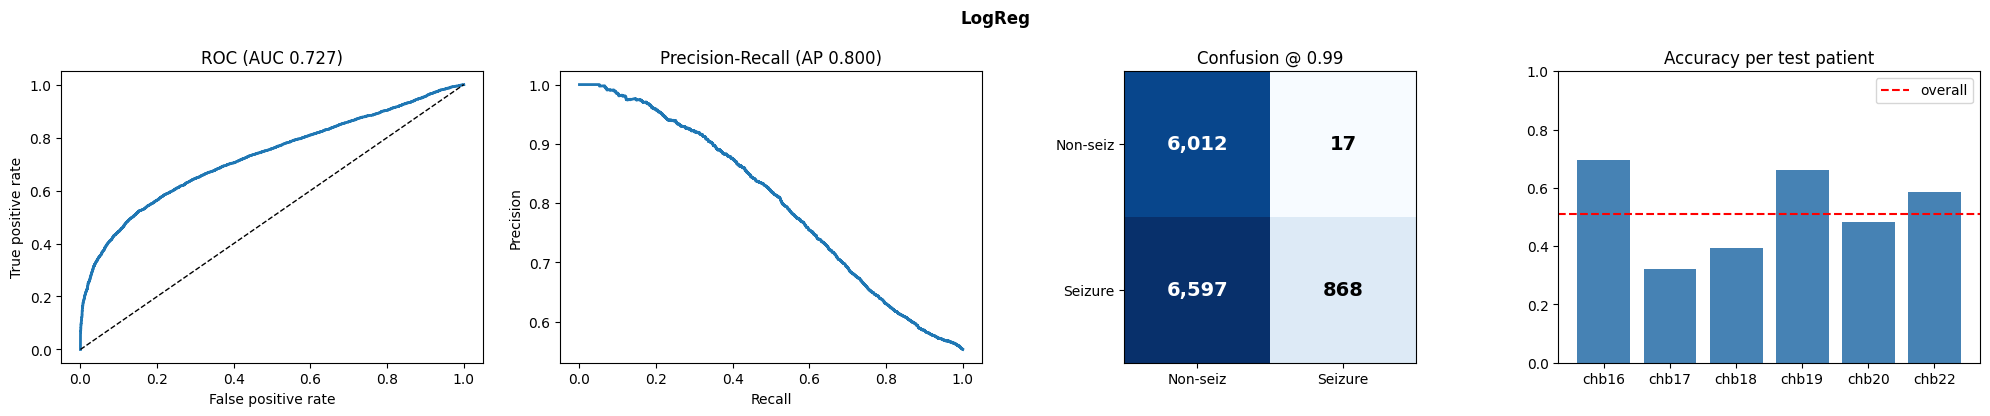

In [14]:
model = LogisticModel.build(C=0.1, max_iter=2000)     # edit any value here
model = train(model, X['train'], y['train'])
scores_lr = evaluate(model, X['validation'], y['validation'], X['test'], y['test'], g['test'])
report(scores_lr); plot(scores_lr)

Fitting XGBoost:   0%|          | 0/1 [00:00<?, ?it/s]

  XGBoost  -  results on UNSEEN test patients
Parameters used: {'n_estimators': 500, 'max_depth': 8, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.6, 'min_child_weight': 10, 'gamma': 0.0, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'random_state': 42}
              Metric  @ 0.50  @ 0.99 (val-tuned)
            Accuracy  0.6827              0.4854
Sensitivity (recall)  0.4816              0.0698
         Specificity  0.9318              1.0000
           Precision  0.8974              1.0000
                  F1  0.6268              0.1305

ROC-AUC 0.7959 | PR-AUC 0.8482 | TP 521 FP 0 TN 6029 FN 6944

Per-patient (tuned threshold):
            n  seizure_frac  accuracy  sensitivity    auc
chb16  2688.0         0.306     0.694        0.000  0.647
chb17  2453.0         0.691     0.309        0.000  0.871
chb18  2451.0         0.617     0.412        0.047  0.843
chb19  1435.0         0.658     0.373        0.047  0.857
chb20  3060.0         0.525     0.476        0.002  0.697
ch

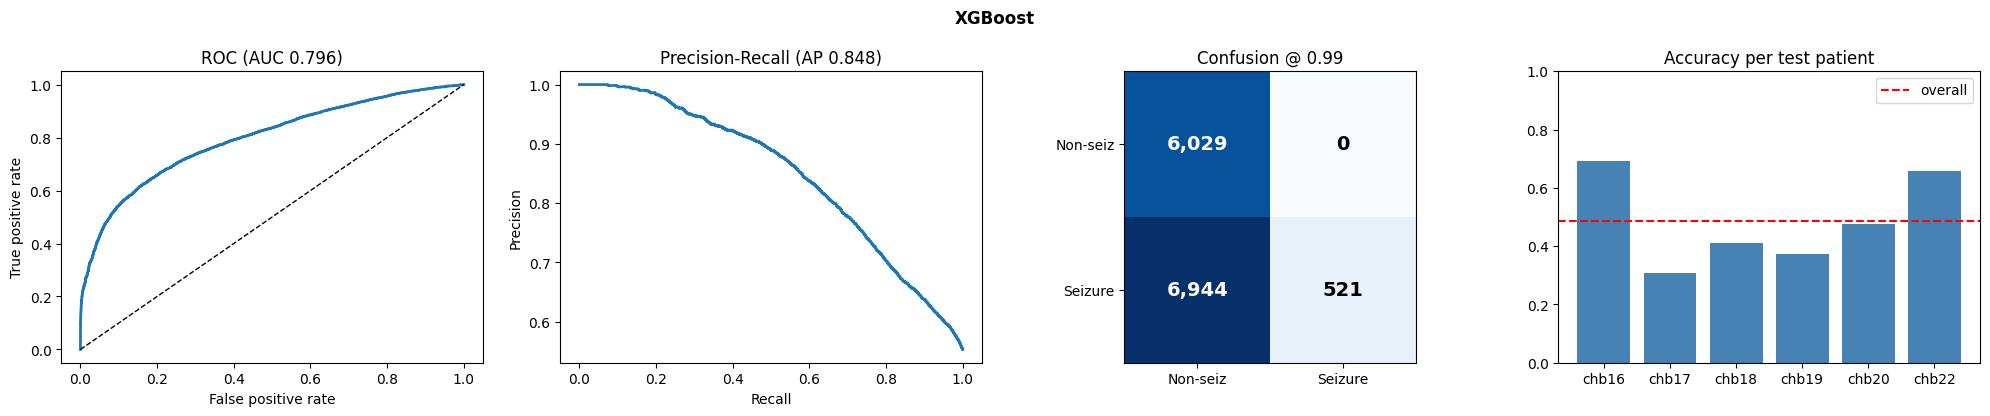

In [15]:
model = XGBoostModel.build(n_estimators=500, max_depth=8, learning_rate=0.05,
                           subsample=0.9, colsample_bytree=0.6, min_child_weight=10,
                           gamma=0.0, reg_alpha=0.1, reg_lambda=1.0)
model = train(model, X['train'], y['train'])
scores_xgb = evaluate(model, X['validation'], y['validation'], X['test'], y['test'], g['test'])
report(scores_xgb); plot(scores_xgb)

  0%|          | 0/10 [00:00<?, ?it/s]

[XGBoost] best CV ROC-AUC = 0.8146
[XGBoost] best parameters : {'n_estimators': 559, 'max_depth': 9, 'learning_rate': 0.012260057359187526, 'subsample': 0.6783931449676581, 'colsample_bytree': 0.33165910223737666, 'min_child_weight': 19, 'gamma': 0.777354579378964, 'reg_alpha': 0.06516990611177176, 'reg_lambda': 3.063462210622083}


Fitting XGBoost:   0%|          | 0/1 [00:00<?, ?it/s]

  XGBoost (Optuna)  -  results on UNSEEN test patients
Parameters used: {'n_estimators': 559, 'max_depth': 9, 'learning_rate': 0.012260057359187526, 'subsample': 0.6783931449676581, 'colsample_bytree': 0.33165910223737666, 'min_child_weight': 19, 'gamma': 0.777354579378964, 'reg_alpha': 0.06516990611177176, 'reg_lambda': 3.063462210622083, 'random_state': 42}
              Metric  @ 0.50  @ 0.01 (val-tuned)
            Accuracy  0.7026              0.5532
Sensitivity (recall)  0.5396              1.0000
         Specificity  0.9045              0.0000
           Precision  0.8749              0.5532
                  F1  0.6675              0.7123

ROC-AUC 0.8026 | PR-AUC 0.8526 | TP 7465 FP 6029 TN 0 FN 0

Per-patient (tuned threshold):
            n  seizure_frac  accuracy  sensitivity    auc
chb16  2688.0         0.306     0.306          1.0  0.636
chb17  2453.0         0.691     0.691          1.0  0.887
chb18  2451.0         0.617     0.617          1.0  0.860
chb19  1435.0       

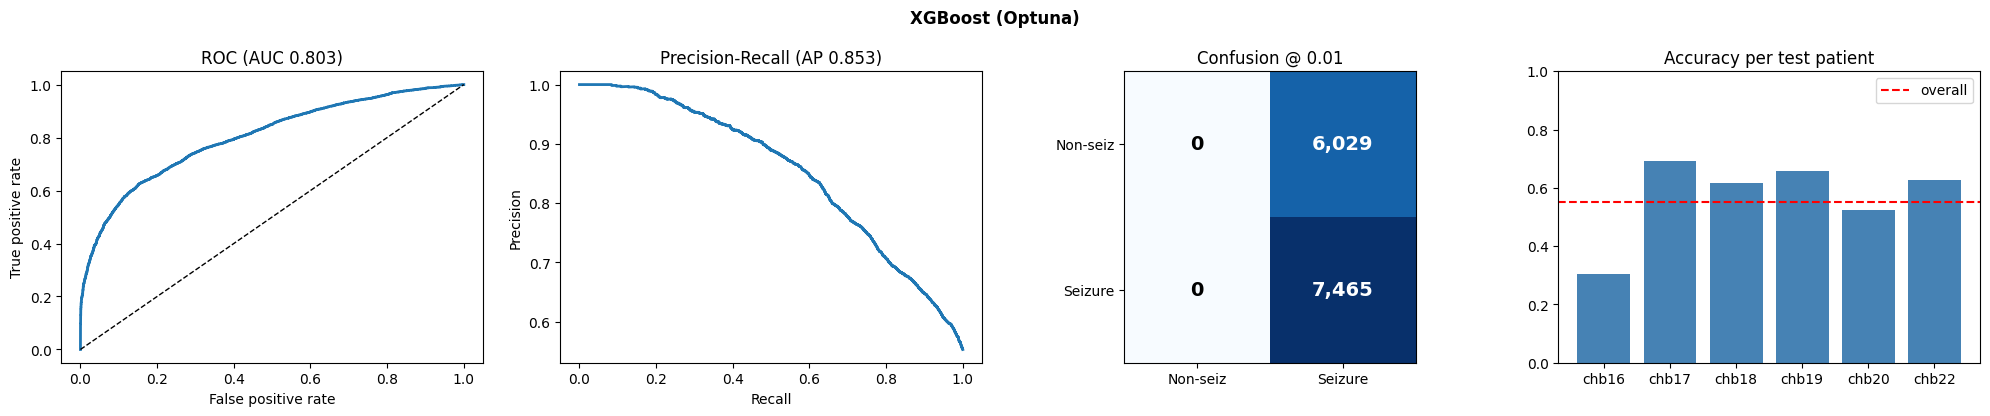

In [16]:
best  = XGBoostModel.best_param(X['train'], y['train'], g['train'], n_trials=10)
model = XGBoostModel.build(**best)
model = train(model, X['train'], y['train'])
scores_xgb_tuned = evaluate(model, X['validation'], y['validation'], X['test'], y['test'], g['test'])
scores_xgb_tuned['name'] = 'XGBoost (Optuna)'
report(scores_xgb_tuned); plot(scores_xgb_tuned)

,Model,Accuracy,Sensitivity,Specificity,F1,ROC_AUC,PR_AUC,Acc_at_0_5
0,XGBoost (Optuna),0.5532,1.0000,0.0000,0.7123,0.8026,0.8526,0.7026
1,XGBoost,0.4854,0.0698,1.0000,0.1305,0.7959,0.8482,0.6827
2,LogReg,0.5099,0.1163,0.9972,0.2079,0.7272,0.7999,0.6707


Best by ROC-AUC: XGBoost (Optuna) (0.8026). Gap to XGBoost: 0.0067 (very small; likely within noise across seeds/patients).


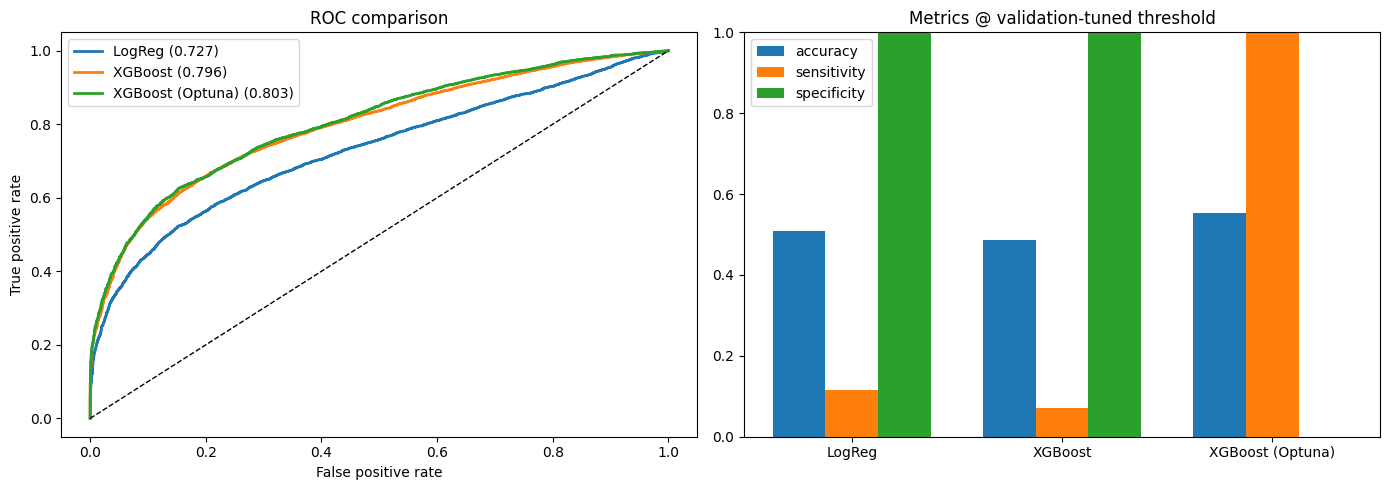

In [17]:
all_scores = [scores_lr, scores_xgb, scores_xgb_tuned]          # add scores_mamba if you ran it
compare(all_scores); plot_compare(all_scores)

In [18]:
raw = load_raw(CSV_PATH)          # read the CSV once  (or: load_raw(CSV_PATH, per_patient_norm='interictal'))


In [19]:
quick = run_loso(raw, LogisticModel, params=dict(C=0.1, max_iter=2000), hold_out=['chb16', 'chb17'])
loso_report(quick)

LOSO LogReg [all]:   0%|          | 0/2 [00:00<?, ?it/s]

  LOSO  |  LogReg | all  |  2 held-out patient(s)
Hyperparameters: fixed, not tuned in this run: {'C': 0.1, 'max_iter': 2000}
  -> valid only if they were NOT chosen by looking at results on these patients.
Threshold per fold: chosen on 2 other patients; the 0.5 columns use no threshold selection.

patient    n  seiz%   AUC  PR-AUC  sens@.5  spec@.5  balAcc@.5  thr  sens@thr  spec@thr  balAcc@thr
  chb16 2688  0.306 0.550   0.408    0.484    0.543      0.513 0.31     0.651     0.354       0.503
  chb17 2453  0.691 0.876   0.930    0.670    0.882      0.776 0.41     0.736     0.839       0.788

Across patients (mean ± SD  [95% bootstrap CI]  (min-max)):
  ROC-AUC              0.713 ± 0.231  [0.550, 0.876]  (0.55-0.88)
  PR-AUC               0.669 ± 0.369  [0.408, 0.930]  (0.41-0.93)
  Sensitivity @0.5     0.577 ± 0.132  [0.484, 0.670]  (0.48-0.67)
  Specificity @0.5     0.713 ± 0.240  [0.543, 0.882]  (0.54-0.88)
  Balanced acc @0.5    0.645 ± 0.186  [0.513, 0.776]  (0.51-0.78)
  Precisi

LOSO XGBoost [all]:   0%|          | 0/20 [00:00<?, ?it/s]

  LOSO  |  XGBoost | all  |  20 held-out patient(s)
Hyperparameters: fixed, not tuned in this run: model defaults
  -> valid only if they were NOT chosen by looking at results on these patients.
Threshold per fold: chosen on 2 other patients; the 0.5 columns use no threshold selection.

patient    n  seiz%   AUC  PR-AUC  sens@.5  spec@.5  balAcc@.5  thr  sens@thr  spec@thr  balAcc@thr
  chb01 6051  0.579 0.862   0.905    0.459    0.973      0.716 0.06     0.867     0.673       0.770
  chb02 1102  0.546 0.891   0.936    0.623    0.996      0.809 0.04     0.884     0.546       0.715
  chb03 3090  0.578 0.859   0.895    0.301    0.979      0.640 0.06     0.730     0.879       0.804
  chb04 6127  0.359 0.905   0.882    0.441    0.994      0.717 0.97     0.010     1.000       0.505
  chb05 3498  0.722 0.951   0.983    0.882    0.871      0.876 0.87     0.824     0.973       0.899
  chb06 9288  0.130 0.536   0.133    0.449    0.570      0.510 0.25     0.612     0.450       0.531
  chb07 4255

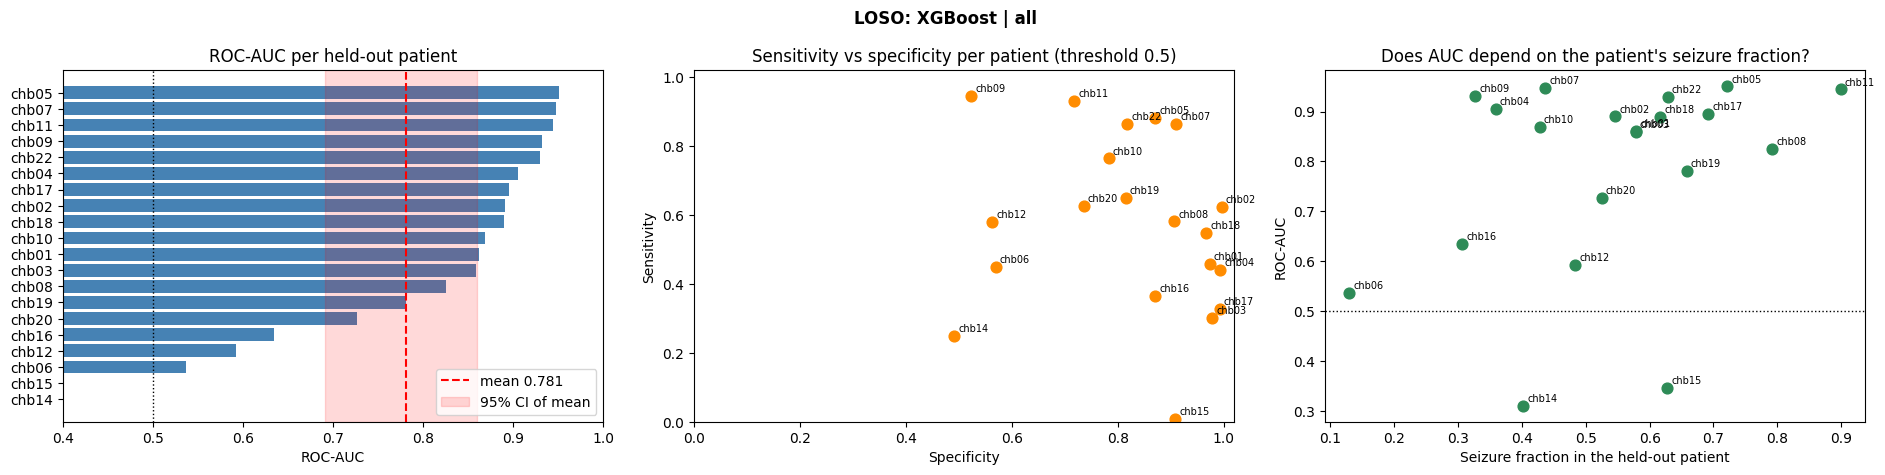

In [20]:
res_xgb = run_loso(raw, XGBoostModel, params={})          # params={} = XGBoost defaults, not tuned
loso_report(res_xgb); plot_loso(res_xgb)

In [21]:
MODEL, PARAMS = XGBoostModel, {}                     # or: LogisticModel, dict(C=0.1, max_iter=2000)
runs = [run_loso(raw, MODEL, params=PARAMS, features=f, label=f'{MODEL.name} | {f}')
        for f in ['conventional', 'snn', 'all']]
loso_compare(runs, baseline=0)                       # baseline = conventional features only

LOSO XGBoost [conventional]:   0%|          | 0/20 [00:00<?, ?it/s]

LOSO XGBoost [snn]:   0%|          | 0/20 [00:00<?, ?it/s]

LOSO XGBoost [all]:   0%|          | 0/20 [00:00<?, ?it/s]

,Run,n,AUC mean ± SD,95% CI,diff vs baseline,diff 95% CI,Wilcoxon p,better in
0,XGBoost | conventional,20,0.784 ± 0.195,"[0.695, 0.861]",-,-,-,-
1,XGBoost | snn,20,0.628 ± 0.108,"[0.582, 0.675]",-0.156,"[-0.212, -0.093]",0.000,3/20 patients
2,XGBoost | all,20,0.781 ± 0.196,"[0.691, 0.859]",-0.002,"[-0.009, +0.004]",0.498,9/20 patients


Baseline = 'XGBoost | conventional'. Differences are paired per patient. A difference whose 95% CI includes 0 is not evidence of a real effect.


,Run,n,AUC mean ± SD,95% CI,diff vs baseline,diff 95% CI,Wilcoxon p,better in
0,XGBoost | conventional,20,0.784 ± 0.195,"[0.695, 0.861]",-,-,-,-
1,XGBoost | snn,20,0.628 ± 0.108,"[0.582, 0.675]",-0.156,"[-0.212, -0.093]",0.000,3/20 patients
2,XGBoost | all,20,0.781 ± 0.196,"[0.691, 0.859]",-0.002,"[-0.009, +0.004]",0.498,9/20 patients
